In [1]:
import pandas as pd

listings=pd.read_csv('listings.csv.gz')
reviews=pd.read_csv('reviews.csv.gz')





In [2]:
"""A2 | Exploration et dictionnaire 3 pts
• Pour listings et reviews, présentez :
– le nombre de lignes et de colonnes ;
– les types ;
– le pourcentage de valeurs manquantes par colonne ;
– le nombre de valeurs distinctes.

• Repérez les colonnes entièrement vides dans votre snapshot : cela varie d’une ville à
l’autre."""


#le nombre de lignes et de colonnes 

review_shape=reviews.shape
listings_shape=listings.shape

#les types

review_dtype=reviews.dtypes.value_counts()
listings_dtype=listings.dtypes.value_counts()

#resumé
def resume(df):
    infos = {'lignes': df.shape[0], 'colonnes': df.shape[1]}
    infos.update(df.dtypes.astype(str).value_counts().to_dict())   # nb de colonnes par type
    return infos

recap = pd.DataFrame({'Table reviews': resume(reviews), 'Table listings': resume(listings)}).fillna(0).astype(int)
display(recap)

,Table reviews,Table listings
lignes,577646,10750
colonnes,6,90
int64,3,24
str,3,29
float64,0,37


In [3]:
 # % valeurs manquantes "listings"

valeurs_manquantesL=(listings.isna().mean() * 100).round(1).sort_values(ascending=False)
valeurs_manquantesL.to_string()
n_empty=listings.isna().all().sum()
empty_cols=list(valeurs_manquantesL.index[valeurs_manquantesL==100])


def categorie(pct):
    if pct == 0:
        return "Complete"
    elif pct < 40:
        return "Mostly complete"
    elif pct < 100:
        return "Almost empty"
    elif pct==100:
        return "Empty"

categories = valeurs_manquantesL.apply(categorie)


ordre = ['Complete', 'Mostly complete', 'Almost empty', 'Empty']

categories.value_counts().reindex(ordre).to_frame('nb_colonnes')



groupes = pd.cut(valeurs_manquantesL,
                 bins=[-1, 0, 10, 50, 99.99, 100],
                 labels=['0 % (complètes)', '0–10 %', '10–50 %', '50–99 %', '100 % (vides)'])
synthese = pd.DataFrame({'% manquants': valeurs_manquantesL, 'groupe': groupes})

recap = synthese.groupby('groupe', observed=False).agg(
    nb_colonnes=('% manquants', 'count'),
    colonnes=('% manquants', lambda s: ', '.join(s.index))
)
with pd.option_context('display.max_colwidth', None):
    display(recap)
    

,nb_colonnes,colonnes
groupe,,
0 % (complètes),45,"availability_60, availability_365, calendar_last_scraped, calculated_host_listings_count, calculated_host_listings_count_entire_homes, calculated_host_listings_count_private_rooms, availability_90, number_of_reviews, number_of_reviews_ltm, number_of_reviews_l30d, availability_eoy, number_of_reviews_ly, estimated_occupancy_l365d, availability_30, calculated_host_listings_count_shared_rooms, id, maximum_nights_avg_ntm, hosts_time_as_host_years, scrape_id, last_scraped, name, description, picture_url, host_id, host_url, host_profile_id, host_profile_url, host_name, hosts_time_as_user_years, hosts_time_as_user_months, hosts_time_as_host_months, minimum_nights_avg_ntm, host_is_superhost, host_picture_url, host_listings_count, host_has_profile_pic, host_identity_verified, neighbourhood_cleansed, latitude, longitude, property_type, room_type, accommodates, listing_url, amenities"
0–10 %,21,"review_scores_cleanliness, reviews_per_month, first_review, last_review, review_scores_rating, review_scores_accuracy, review_scores_checkin, review_scores_communication, review_scores_value, review_scores_location, license, beds, maximum_maximum_nights, minimum_maximum_nights, maximum_minimum_nights, minimum_minimum_nights, maximum_nights, minimum_nights, has_availability, bedrooms, bathrooms_text"
10–50 %,9,"host_about, price_quote_total_price, price_quote_price_per_night, price, estimated_revenue_l365d, price_quote_checkin_date, price_quote_checkout_date, price_quote_raw, host_location"
50–99 %,1,source
100 % (vides),14,"host_verifications, bathrooms, host_acceptance_rate, host_response_rate, host_response_time, host_neighbourhood, host_total_listings_count, calendar_updated, host_since, neighbourhood, host_thumbnail_url, neighbourhood_group_cleansed, instant_bookable, neighborhood_overview"


In [4]:
# % valeurs manquantes reviews


valeurs_manquantesR=(reviews.isna().mean() * 100).round(2).sort_values(ascending=False)
valeurs_manquantesR.to_string()
n_empty=reviews.isna().all().sum()

display(pd.DataFrame({"colonne": (reviews.isna().mean() * 100).round(2).index,
                      "% de v.manquante": (reviews.isna().mean() * 100).round(2).values}))




,colonne,% de v.manquante
0,listing_id,0.00
1,id,0.00
2,date,0.00
3,reviewer_id,0.00
4,reviewer_name,0.00
5,comments,0.17


In [5]:
#nombre de valeurs distinctes: listings, reviews

valeurs_dis_list=listings.nunique()

valeurs_dis_rev=reviews.nunique()

with pd.option_context('display.max_rows', None):
    display(pd.DataFrame(valeurs_dis_list.sort_values(ascending=False), columns=['Valeurs uniques']))

display(pd.DataFrame(valeurs_dis_rev.sort_values(ascending=False),columns=['Valeurs uniques']))

,Valeurs uniques
id,10612
listing_url,10612
picture_url,10561
name,10248
description,10091
amenities,10048
host_id,9231
host_url,9231
host_profile_id,9231
host_profile_url,9231


,Valeurs uniques
id,554973
comments,536780
reviewer_id,533234
reviewer_name,71244
listing_id,11325
date,6659


In [6]:
#dictionnaire de données pour les colonnes que vous retenez (25 à 35). Pour
#chaque colonne : nom, signification, type d’origine, type cible, unité, pourcentage de manquants, décision (garder, transformer, écarter)

#columns, draft
colonnes=[
'number_of_reviews_ltm',
'last_review',
'availability_365',
'calculated_host_listings_count',
'room_type',
'price',
'accommodates',
'hosts_time_as_host_months',
 'hosts_time_as_host_years',
'amenities',
'minimum_nights',
'license',
'number_of_reviews_ltm',
'last_review',
'availability_365',
'host_id',
'id',
'estimated_revenue_l365d',
'estimated_occupancy_l365d',
'hosts_time_as_host_months',
'neighbourhood_cleansed',
'bedrooms',
'last_scraped',
'host_is_superhost',
'first_review',
'bathrooms_text'
]
print(len(colonnes))

# remove doubles 

colonnes=list(dict.fromkeys(i.strip ()for i in colonnes))
len(colonnes)



26


22

In [ ]:
"""
Dictionnaire de données — listings Airbnb (Amsterdam), scrape du 2026-09-17.
Source : listings.csv.gz (10 750 lignes x 90 colonnes ; 22 colonnes documentées ici).

Les pourcentages de manquants sont calculés sur les valeurs brutes (NaN) du fichier.
Les anomalies repérées à l'inspection sont signalées dans 'remarques'.
"""

import pandas as pd

dictionnaire_donnees = {
    # ------------------------------------------------------------------ Identifiants
    "id": {
        "nom": "id",
        "signification": "Identifiant unique de l'annonce Airbnb",
        "type_origine": "int64",
        "type_cible": "int64 (identifiant, non utilisé comme variable numérique)",
        "unite": "aucune (identifiant)",
        "pct_manquants": 0.0,
        "decision": "garder",
        "remarques": "138 doublons d'id (dont 106 lignes entièrement dupliquées) : dédoublonner. "
                     "Valeurs > 2^31, rester en int64.",
    },
    "host_id": {
        "nom": "host_id",
        "signification": "Identifiant unique de l'hôte",
        "type_origine": "int64",
        "type_cible": "int64 (identifiant, clé de regroupement)",
        "unite": "aucune (identifiant)",
        "pct_manquants": 0.0,
        "decision": "garder",
        "remarques": "9 231 hôtes distincts. Sert à regrouper les annonces par hôte, "
                     "pas à entrer dans un modèle.",
    },
    # ------------------------------------------------------------------ Hôte
    "host_is_superhost": {
        "nom": "host_is_superhost",
        "signification": "Indique si l'hôte a le statut Superhost",
        "type_origine": "str (object)",
        "type_cible": "bool",
        "unite": "aucune (binaire)",
        "pct_manquants": 0.0,
        "decision": "transformer",
        "remarques": "10 libellés différents pour 2 valeurs : "
                     "vrai = {'t','TRUE','yes','Vrai','1'} ; faux = {'f','FALSE','no','Faux','0'}.",
    },
    "hosts_time_as_host_years": {
        "nom": "hosts_time_as_host_years",
        "signification": "Ancienneté de l'hôte : nombre d'années entières (0 à 15)",
        "type_origine": "int64",
        "type_cible": "int64 (fusionné en ancienneté totale)",
        "unite": "années",
        "pct_manquants": 0.0,
        "decision": "transformer",
        "remarques": "À combiner avec la composante mois : "
                     "anciennete_mois = years * 12 + months.",
    },
    "hosts_time_as_host_months": {
        "nom": "hosts_time_as_host_months",
        "signification": "Ancienneté de l'hôte : mois restants après les années entières (0 à 11)",
        "type_origine": "int64",
        "type_cible": "int64 (fusionné en ancienneté totale)",
        "unite": "mois",
        "pct_manquants": 0.0,
        "decision": "transformer",
        "remarques": "Ce n'est PAS l'ancienneté totale en mois (max = 11) : "
                     "c'est le reste après hosts_time_as_host_years.",
    },
    "calculated_host_listings_count": {
        "nom": "calculated_host_listings_count",
        "signification": "Nombre d'annonces actives de l'hôte (calculé par Inside Airbnb)",
        "type_origine": "int64",
        "type_cible": "int64",
        "unite": "nombre d'annonces",
        "pct_manquants": 0.0,
        "decision": "garder",
        "remarques": "Distribution très asymétrique (8 738 hôtes à 1 annonce, max 24) ; "
                     "utile pour distinguer particuliers et multi-propriétaires.",
    },
    # ------------------------------------------------------------------ Logement
    "room_type": {
        "nom": "room_type",
        "signification": "Type de logement proposé",
        "type_origine": "str (object)",
        "type_cible": "category (4 modalités)",
        "unite": "aucune (catégorielle)",
        "pct_manquants": 0.0,
        "decision": "transformer",
        "remarques": "10 libellés bruts à harmoniser (casse, variantes) vers : "
                     "'Entire home/apt', 'Private room', 'Hotel room', 'Shared room'. "
                     "Ex. 'entire home/apt', 'Entire home' -> 'Entire home/apt' ; "
                     "'Private', 'private room' -> 'Private room'.",
    },
    "accommodates": {
        "nom": "accommodates",
        "signification": "Capacité d'accueil maximale du logement",
        "type_origine": "int64",
        "type_cible": "int64",
        "unite": "personnes",
        "pct_manquants": 0.0,
        "decision": "garder",
        "remarques": "Valeurs aberrantes : 19 annonces à 0 et 14 à 99. "
                     "À traiter (mise à NaN puis imputation, ou suppression).",
    },
    "bedrooms": {
        "nom": "bedrooms",
        "signification": "Nombre de chambres",
        "type_origine": "float64",
        "type_cible": "Int64 (entier nullable)",
        "unite": "nombre de chambres",
        "pct_manquants": 0.27,
        "decision": "garder",
        "remarques": "227 annonces à 0 chambre (studios, plausible). Maximum 17 : à vérifier. "
                     "Peu de manquants : imputation par la médiane ou le mode.",
    },
    "bathrooms_text": {
        "nom": "bathrooms_text",
        "signification": "Description textuelle des salles de bain (nombre + privée/partagée)",
        "type_origine": "str (object)",
        "type_cible": "2 variables : nb_salles_de_bain (float) + sdb_partagee (bool)",
        "unite": "nombre de salles de bain",
        "pct_manquants": 0.07,
        "decision": "transformer",
        "remarques": "Extraire le nombre par regex ; 'Half-bath' / 'Private half-bath' / "
                     "'Shared half-bath' = 0.5. Le mot 'shared' donne l'indicateur partagé. "
                     "Valeurs extrêmes : 12 et 17 salles de bain.",
    },
    "amenities": {
        "nom": "amenities",
        "signification": "Liste des équipements de l'annonce",
        "type_origine": "str (liste JSON sérialisée)",
        "type_cible": "list[str] -> nb_equipements (int) et/ou indicateurs binaires ciblés",
        "unite": "nombre d'équipements (après transformation)",
        "pct_manquants": 0.0,
        "decision": "transformer",
        "remarques": "Parser avec json.loads. 10 048 combinaisons uniques : "
                     "ne pas l'encoder telle quelle ; créer un compteur et quelques "
                     "indicateurs (climatisation, parking, vue canal...).",
    },
    "neighbourhood_cleansed": {
        "nom": "neighbourhood_cleansed",
        "signification": "Quartier de l'annonce (nom normalisé par Inside Airbnb)",
        "type_origine": "str (object)",
        "type_cible": "category",
        "unite": "aucune (catégorielle)",
        "pct_manquants": 0.0,
        "decision": "transformer",
        "remarques": "83 libellés bruts pour un nombre bien plus faible de quartiers réels : "
                     "espaces en début/fin (34 cas), casse et tirets incohérents "
                     "('Centrum-West' / 'Centrum West' / ' centrum-west '). "
                     "Après strip + minuscules il reste encore 36 variantes : normaliser aussi "
                     "tirets et espaces.",
    },
    # ------------------------------------------------------------------ Réservation / règles
    "minimum_nights": {
        "nom": "minimum_nights",
        "signification": "Durée minimale de séjour exigée",
        "type_origine": "float64",
        "type_cible": "Int64 (entier nullable)",
        "unite": "nuits",
        "pct_manquants": 2.51,
        "decision": "transformer",
        "remarques": "21 valeurs négatives (-1, -2) = erreurs de saisie. Valeurs extrêmes jusqu'à 800 "
                     "(séjours longue durée ?). Mettre les négatifs à NaN, envisager un plafonnement.",
    },
    "license": {
        "nom": "license",
        "signification": "Numéro de licence / enregistrement de location touristique (Amsterdam)",
        "type_origine": "str (object)",
        "type_cible": "category : 'valide' / 'exempt' / 'absente' / 'format_invalide'",
        "unite": "aucune (catégorielle)",
        "pct_manquants": 4.39,
        "decision": "transformer",
        "remarques": "Le numéro lui-même est quasi unique (9 092 valeurs distinctes) : inutilisable "
                     "tel quel. 613 annonces (5,70 %) valent 'Exempt'. Format attendu "
                     "'0363 XXXX XXXX XXXX XXXX' : 8 369 valeurs conformes ; le reste inclut des "
                     "préfixes 'NLD', des espaces manquants et des valeurs factices ('ABCD 1234 ...').",
    },
    "availability_365": {
        "nom": "availability_365",
        "signification": "Nombre de jours disponibles à la réservation sur les 365 prochains jours",
        "type_origine": "int64",
        "type_cible": "int64",
        "unite": "jours (0 à 365)",
        "pct_manquants": 0.0,
        "decision": "garder",
        "remarques": "Plage cohérente. Une disponibilité de 0 peut signifier annonce complète "
                     "ou calendrier bloqué.",
    },
    # ------------------------------------------------------------------ Prix et revenus
    "price": {
        "nom": "price",
        "signification": "Prix par nuit affiché pour l'annonce",
        "type_origine": "str (object)",
        "type_cible": "float64",
        "unite": "devise par nuit (symbole '$' dans le fichier ; devise réelle à confirmer)",
        "pct_manquants": 42.92,
        "decision": "transformer",
        "remarques": "Formats mixtes : '$358.00' (5 974), '250 dollars', 'CAD 292', "
                     "'507,50 $', '305.50' brut, et 32 valeurs négatives ('-$219.67'). "
                     "Nettoyer par regex, puis traiter les valeurs négatives (erreur de signe ?), "
                     "les 22 prix à 0 et le maximum aberrant 99 999. "
                     "Manquants très élevés (43 %) : variable cible potentielle, "
                     "ne pas imputer sans réflexion.",
    },
    "estimated_revenue_l365d": {
        "nom": "estimated_revenue_l365d",
        "signification": "Revenu estimé sur les 365 derniers jours (prix x nuits occupées estimées)",
        "type_origine": "float64",
        "type_cible": "float64",
        "unite": "devise (même que price)",
        "pct_manquants": 42.92,
        "decision": "garder",
        "remarques": "Les manquants coïncident exactement avec ceux de price (42,92 %) : "
                     "l'estimation dépend du prix. Valeurs de 0 à 201 226, médiane ~10 666. "
                     "Manquants de structure, pas du hasard.",
    },
    "estimated_occupancy_l365d": {
        "nom": "estimated_occupancy_l365d",
        "signification": "Nombre de nuits occupées estimé sur les 365 derniers jours",
        "type_origine": "int64",
        "type_cible": "int64",
        "unite": "nuits (0 à 255)",
        "pct_manquants": 0.0,
        "decision": "garder",
        "remarques": "Estimation (modèle Inside Airbnb basé sur les avis), pas une observation. "
                     "Plafonnée à 255 nuits.",
    },
    # ------------------------------------------------------------------ Avis
    "number_of_reviews_ltm": {
        "nom": "number_of_reviews_ltm",
        "signification": "Nombre d'avis reçus sur les 12 derniers mois (last twelve months)",
        "type_origine": "int64",
        "type_cible": "int64",
        "unite": "nombre d'avis",
        "pct_manquants": 0.0,
        "decision": "garder",
        "remarques": "Médiane 2, moyenne 9,7, maximum 878 : distribution très asymétrique, "
                     "valeurs extrêmes à vérifier (annonces à très forte rotation ?).",
    },
    "first_review": {
        "nom": "first_review",
        "signification": "Date du premier avis reçu par l'annonce",
        "type_origine": "str (object)",
        "type_cible": "datetime64[ns]",
        "unite": "date (AAAA-MM-JJ)",
        "pct_manquants": 9.44,
        "decision": "transformer",
        "remarques": "Format ISO homogène. Les manquants correspondent aux annonces sans aucun avis "
                     "(mêmes lignes que last_review). Dériver l'ancienneté de l'annonce "
                     "(last_scraped - first_review). 54 lignes ont first_review > last_review.",
    },
    "last_review": {
        "nom": "last_review",
        "signification": "Date du dernier avis reçu par l'annonce",
        "type_origine": "str (object)",
        "type_cible": "datetime64[ns]",
        "unite": "date (AAAA-MM-JJ)",
        "pct_manquants": 9.44,
        "decision": "transformer",
        "remarques": "Formats mixtes : 53 dates au format JJ/MM/AAAA à côté du format ISO "
                     "(le jour est toujours en premier, aucun mois > 12). "
                     "22 dates postérieures à la date du scrape (jusqu'en 2028) : erreurs à mettre à NaN. "
                     "Dériver 'jours depuis le dernier avis'.",
    },
    "last_scraped": {
        "nom": "last_scraped",
        "signification": "Date de collecte des données par Inside Airbnb",
        "type_origine": "str (object)",
        "type_cible": "datetime64[ns] (constante de référence)",
        "unite": "date (AAAA-MM-JJ)",
        "pct_manquants": 0.0,
        "decision": "écarter",
        "remarques": "Une seule valeur (2026-09-17) : aucune variance, inutile comme variable. "
                     "À conserver uniquement comme date de référence pour calculer des durées.",
    },
}


def en_dataframe() -> pd.DataFrame:
    """Retourne le dictionnaire sous forme de tableau (une ligne par variable)."""
    return pd.DataFrame.from_dict(dictionnaire_donnees, orient="index").reset_index(drop=True)


def verifier_manquants(chemin_csv: str) -> pd.DataFrame:
    """Recalcule le % de manquants depuis le fichier et le compare au dictionnaire."""
    df = pd.read_csv(chemin_csv, compression="infer", low_memory=False)
    out = []
    for col, meta in dictionnaire_donnees.items():
        reel = round(df[col].isna().mean() * 100, 2)
        out.append({"variable": col, "dictionnaire": meta["pct_manquants"], "recalcule": reel,
                    "ecart": round(reel - meta["pct_manquants"], 2)})
    return pd.DataFrame(out)


if __name__ == "__main__":
    pd.set_option("display.max_colwidth", 60, "display.width", 200)
    print(en_dataframe()[["nom", "type_origine", "type_cible", "unite", "pct_manquants", "decision"]])

In [7]:
#nouvelle table 'listings' sans colonnes vides
## drop 100% empty columns -77 columns now

new_table=listings.drop(columns=empty_cols)


round(new_table.notna().mean()*100,1).sort_values(ascending=True)


print(round(new_table.notna().mean()*100,1).sort_values(ascending=True).to_string())




source                                           46.7
host_about                                       53.0
price_quote_price_per_night                      57.0
price_quote_total_price                          57.0
estimated_revenue_l365d                          57.1
price                                            57.1
price_quote_raw                                  58.3
price_quote_checkout_date                        58.3
price_quote_checkin_date                         58.3
host_location                                    85.6
review_scores_cleanliness                        90.5
review_scores_location                           90.6
review_scores_checkin                            90.6
review_scores_accuracy                           90.6
review_scores_rating                             90.6
first_review                                     90.6
review_scores_value                              90.6
review_scores_communication                      90.6
last_review                 

In [8]:
"""A3: conversion
""price=objet(texte), convertir en float et verifier que rien n'est perdu"""

colonnes=list(dict.fromkeys(i.strip ()for i in colonnes))

def convertir_prix(x):
    if pd.isna(x):
        return None
    s = str(x).strip()
    s = s.replace('CAD', '').replace('dollars', '').replace('$', '').replace(' ', '')
    if ',' in s and '.' in s:         
        s = s.replace(',', '')
    elif ',' in s:
        apres_virgule = s.split(',')[1]       # après la virgule
        if len(apres_virgule) == 3:           # 3 ch → milliers  
            s = s.replace(',', '')            
        else:                                 # 2 ch → centimes 
            s = s.replace(',', '.')          
    try:
            return float(s)
    except ValueError:
            return None

new_table['price']=new_table['price'].apply(convertir_prix)

price_values1=listings['price'].isna().sum()
price_values2=new_table['price'].isna().sum()


summary_table={'avant':[price_values1,listings['price'].dtype ], 
               'apres':[price_values2,new_table['price'].dtype] }

print("Convertir colonne 'price' en float")

pd.DataFrame(summary_table,index=['lignes', 'dtype'])

Convertir colonne 'price' en float


,avant,apres
lignes,4614,4614
dtype,object,float64


In [9]:
"""'host_response_rate', 'host_acceptance_rate' sont vides"""

"""host_is_superhost-not empty contains mostly t and f but also'no, faux, fasleetc...),
instant_bookable-vide-empty"""



def convertir_truefalse(i):
    i=str(i)
    if i=='Faux' or i=='no' or i=='FALSE'or i=='0':        
        i = 'f'
    elif  i=='Vrai' or i=='yes' or i=='TRUE'or i=='1':
        i = 't'
    return i 

#restore the column if i repeat the conversion

new_table['host_is_superhost'] = listings.loc[new_table.index, 'host_is_superhost']

new_table['host_is_superhost']=new_table['host_is_superhost'].apply(convertir_truefalse)
new_table['host_is_superhost'] = new_table['host_is_superhost'].map({'t': True, 'f': False}).astype('boolean')


superhost_values_before=listings['host_is_superhost'].value_counts(dropna=False).count()
superhost_values_after=new_table['host_is_superhost'].value_counts(dropna=False).count()

dtype_before=listings['host_is_superhost'].dtype
dtype_after=new_table['host_is_superhost'].dtype


total_values_before=listings['host_is_superhost'].value_counts(dropna=False).sum()
total_values_after=new_table['host_is_superhost'].value_counts(dropna=False).sum()

print("Convertir colonne 'host_is_superhost' ")
summary=pd.DataFrame({'dtype':[dtype_before,dtype_after], 
                      'v_dist':[superhost_values_before,superhost_values_after],
                      'total':[total_values_before,total_values_after]},index=['avant', 'apres'])

display(summary)

Convertir colonne 'host_is_superhost' 


,dtype,v_dist,total
avant,object,10,10750
apres,boolean,2,10750


In [10]:
"""Dates: last_scraped,first_review,last_review-all not empty"""
"""A3 — Conversion des dates : last_scraped, first_review, last_review
Deux formats mélangés : ISO (2026-09-12) et français (12/09/2026).
On lit chaque format avec sa propre règle pour ne pas inverser jour et mois.
Contrôle : nombre de dates renseignées avant / après (aucune ne doit devenir illisible)."""

cols_dates = ['last_scraped', 'first_review', 'last_review']
summary_dates = {}

for i in cols_dates:
    avant = new_table[i].count()
    dtype1 = listings[i].dtype

    iso = pd.to_datetime(new_table[i], format='%Y-%m-%d', errors='coerce')   # 2026-09-12
    fr  = pd.to_datetime(new_table[i], format='%d/%m/%Y', errors='coerce')   # 12/09/2026
    new_table[i] = iso.fillna(fr)          # format ISO, sinon format français

    apres = new_table[i].count()
    summary_dates[i] = {'avant': avant, 'après': apres,
                        'dtype avant': dtype1, 'dtype après': new_table[i].dtype}

display(pd.DataFrame(summary_dates).T)



,avant,après,dtype avant,dtype après
last_scraped,10750,10750,object,datetime64[ns]
first_review,9735,9735,object,datetime64[ns]
last_review,9735,9735,object,datetime64[ns]


In [11]:
"""A3 — bathrooms_text : texte → nombre de salles de bain + indicateur 'partagée'
Exemples de valeurs : '1 bath', '1.5 baths', '1 shared bath', 'Half-bath'
- nmb_bathrooms : on extrait le nombre ; 'half' (sans chiffre) → 0.5
- partage : True si la salle de bain est partagée ('shared')
Contrôle : nombre de textes renseignés dont on n'a pas pu extraire de nombre."""

new_table['nmb_bathrooms'] = new_table['bathrooms_text'].str.extract(r'(\d+\.?\d*)')[0].astype(float)
half = new_table['bathrooms_text'].str.contains("half", case=False, na=False)
new_table.loc[half, 'nmb_bathrooms'] = 0.5
new_table['partage'] = new_table['bathrooms_text'].str.contains('shared', case=False, na=False)

# contrôle : texte présent mais nombre non extrait = valeur illisible
illisibles = (new_table['bathrooms_text'].notna() & new_table['nmb_bathrooms'].isna()).sum()

print(f"Textes renseignés          : {new_table['bathrooms_text'].notna().sum()}")
print(f"Valeurs illisibles         : {illisibles}")
print(f"Demi-salles de bain (0.5)  : {half.sum()}")
print(f"Salles de bain partagées   : {new_table['partage'].sum()}")
display(new_table[['bathrooms_text', 'nmb_bathrooms', 'partage']].head())

colonnes.extend(['nmb_bathrooms', 'partage'])

Textes renseignés          : 10742
Valeurs illisibles         : 0
Demi-salles de bain (0.5)  : 47
Salles de bain partagées   : 560


,bathrooms_text,nmb_bathrooms,partage
0,1 bath,1.0,False
1,2 baths,2.0,False
2,1 bath,1.0,False
3,1 bath,1.0,False
4,1 bath,1.0,False


In [12]:
"""amenities : liste écrite comme une chaîne (texte) --> liste Python, puis nombre d'équipements"""

import json
new_table['amenities_'] = new_table['amenities'].apply(json.loads)  
new_table['n_amenities'] = new_table['amenities_'].apply(len)       

print("Nombre d'équipements : min", new_table['n_amenities'].min(), ", max", new_table['n_amenities'].max())
print("Annonces sans équipement :", (new_table['n_amenities'] == 0).sum())
display(new_table[['amenities_', 'n_amenities']].head())

colonnes.extend(['amenities_', 'n_amenities'])

Nombre d'équipements : min 0 , max 99
Annonces sans équipement : 5


,amenities_,n_amenities
0,"[Bed linens, Private patio or balcony, Canal v...",40
1,"[Bed linens, Canal view, Smoke alarm, Mini fri...",34
2,"[Bed linens, Private patio or balcony, Smoke a...",36
3,"[Bed linens, Private patio or balcony, Smoke a...",33
4,"[Kitchen, Dedicated workspace, TV, Smoke alarm...",6


In [13]:
"""Modalités :
room_type (libellés écrits de plusieurs façons, ex. 'ENTIRE HOME/APT', 'Private') --> une seule écriture par modalité"""

new_table['room_type'] = new_table['room_type'].str.lower()          # tout en minuscules

r = {'entire home': 'entire home/apt', 'private': 'private room'}     # libellés incomplets --> libellé complet
new_table['room_type'] = new_table['room_type'].replace(r)

n_before = listings['room_type'].value_counts().sum()
cat_before = listings['room_type'].value_counts().count()

n_after = new_table['room_type'].value_counts().sum()
cat_after = new_table['room_type'].value_counts().count()

summary = pd.DataFrame({'avant': [n_before, cat_before], 'apres': [n_after, cat_after]},
                       index=['Valeurs renseignées', 'Libellés distincts'])
display(summary)

print("Modalités finales :")
display(new_table['room_type'].value_counts().to_frame())




,avant,apres
Valeurs renseignées,10750,10750
Libellés distincts,10,4


Modalités finales :


,count
room_type,
entire home/apt,8689
private room,2014
hotel room,24
shared room,23


In [14]:
""" A4 | Valeurs manquantes 
• Pour chaque colonne retenue qui contient des manquants, choisissez une stratégie parmi
celles vues en cours :
• Présentez vos choix dans un tableau : colonne, pourcentage de manquants, stratégie,
justification.
• Interrogez-vous sur la cause des manquants. Exemple : un prix manquant peut
correspondre à une annonce non réservable au moment du snapshot."""

#je creer une nouvelle table à partir des colonnes j'ai selectionné avant

colonnes=list(dict.fromkeys(colonnes))
nouvelle_table=new_table[colonnes].copy()

#valeurs manq apparaissent des les colonnes suivantes: 'last_review' ,'first_review','price',
#'estimated_revenue_l365d', "minimum_nights",'license','bedrooms', 'bathrooms_text','nmb_bathrooms'

manquants = pd.DataFrame({
    'nb_manquants': nouvelle_table.isna().sum(),
    '% manquants' : round(nouvelle_table.isna().mean() *100 ,2)
})
manquants[manquants['nb_manquants'] > 0].sort_values('nb_manquants',ascending=False)

strategies = {
    'price':                   'NaN conservés + indicateur prix_renseigne',
    'estimated_revenue_l365d': 'NaN conservés (filtrer avec prix_renseigne)',
    'last_review':             'NaN conservés + indicateur a_des_avis',
    'first_review':            'NaN conservés + indicateur a_des_avis',
    'license':                 'Nouvelle variable statut_licence (non renseigné / exempté / renseigné)',
    'minimum_nights':          'Imputation par minimum_nights_avg_ntm (même annonce)',
    'bedrooms':                'Private room → 1 ; entire home/apt → NaN conservés',
    'bathrooms_text':          'NaN conservés (variable brute)',
    'nmb_bathrooms':           'Imputation par 1',
}

justifications = {
    'price':                   'Prix absent si calendrier fermé (92 % des cas) ; imputer fausserait les revenus',
    'estimated_revenue_l365d': 'Mêmes lignes que price (revenu = nuits × prix)',
    'last_review':             "Annonce sans aucun avis : pas de date à inventer",
    'first_review':            "Annonce sans aucun avis : pas de date à inventer",
    'license':                 "Le manquant est une information en soi (pas de numéro déclaré)",
    'minimum_nights':          'Moyenne calendaire de la même annonce = estimation la plus fiable',
    'bedrooms':                'Une chambre louée = au moins une chambre ; reste négligeable (0,1 %)',
    'bathrooms_text':          'Déjà exploitée en A3 (nmb_bathrooms, partage)',
    'nmb_bathrooms':           'Un logement loué a au moins une salle de bain (7 hotel rooms, 1 private room)',
}

manquants['stratégie']     = manquants.index.map(strategies)
manquants['justification'] = manquants.index.map(justifications)

with pd.option_context('display.max_colwidth', None):
    display(manquants)


,nb_manquants,% manquants,stratégie,justification
number_of_reviews_ltm,0,0.00,NaN,NaN
last_review,1015,9.44,NaN conservés + indicateur a_des_avis,Annonce sans aucun avis : pas de date à inventer
availability_365,0,0.00,NaN,NaN
calculated_host_listings_count,0,0.00,NaN,NaN
room_type,0,0.00,NaN,NaN
price,4614,42.92,NaN conservés + indicateur prix_renseigne,Prix absent si calendrier fermé (92 % des cas) ; imputer fausserait les revenus
accommodates,0,0.00,NaN,NaN
hosts_time_as_host_months,0,0.00,NaN,NaN
hosts_time_as_host_years,0,0.00,NaN,NaN
amenities,0,0.00,NaN,NaN


In [15]:
# 'last_review '/'first_review':on garde NAN mais on cree une nouvelle cols 'a_des_avis' 
#pour avoir des info sur les apparts sans reviews

nouvelle_table.isna().sum()
nouvelle_table['a_des_avis']=nouvelle_table['first_review'].notna()

display(nouvelle_table['a_des_avis'].value_counts().to_frame())

,count
a_des_avis,
True,9735
False,1015


In [16]:
# "price" et 'estimated_revenue_l365d': valeurs manq=apparts avec calendrier fermée, on va garder nan et on cree une nouvelle col ='prix_renseigne'

nouvelle_table['prix_renseigne']=nouvelle_table['price'].notna()

display(nouvelle_table['prix_renseigne'].value_counts().to_frame())


,count
prix_renseigne,
True,6136
False,4614


In [17]:
# "minimum_nights" a des val manquantes, on va utiliser la col "minimum_nights_avg_ntm" pour prendre leur valeur

masque=nouvelle_table["minimum_nights" ].isna()

remplir=listings["minimum_nights_avg_ntm"][masque]

nouvelle_table.loc[ masque,"minimum_nights"]=remplir

nouvelle_table["minimum_nights" ].isna().sum()


avant=new_table["minimum_nights" ].isna().sum()
apres=nouvelle_table["minimum_nights" ].isna().sum()
summary=pd.DataFrame({'avant':avant, 'apres':apres}, index=['valeurs manquantes'])
display(summary)

,avant,apres
valeurs manquantes,270,0


In [18]:
#'license' -->472 valeurs manq--> une nouvelle col: 'statut_licence' avec trois valeurs:'renseigné','exempté','non renseigné '
masque1=nouvelle_table['license'].isna()
nouvelle_table.loc[masque1,'statut_licence']="non renseigné"


masque2=nouvelle_table['license'].str.contains('exempt',case=False, na=False)
nouvelle_table.loc[masque2,'statut_licence']="exempté"


masque3=nouvelle_table['statut_licence'].isna()
nouvelle_table.loc[masque3,'statut_licence']="renseigné"



summary= nouvelle_table['statut_licence'].value_counts().to_frame()
display(summary)

,count
statut_licence,
renseigné,9665
exempté,613
non renseigné,472


In [19]:
# bedrooms : 29 NaN — 17 en « private room », 12 en « entire home/apt »
# private room → 1 : une chambre louée = au moins une chambre (déduction logique)
# entire home/apt → NaN conservés : nombre de chambres inconnu, effectif négligeable

condition=(nouvelle_table['bedrooms'].isna())& (nouvelle_table['room_type']=='private room')
nouvelle_table.loc[condition, 'bedrooms']=1

avant=new_table['bedrooms'].isna().sum()
apres=nouvelle_table['bedrooms'].isna().sum()

summary=pd.DataFrame({'avant':avant, 'apres':apres}, index=['valeurs manquantes'])
display(summary)

,avant,apres
valeurs manquantes,29,12


In [20]:


#'bathrooms_text' et 'nmb_bathrooms' 8 vals manqs. 'bathrooms_text'-deja traité dans la partie A3. 
#Pour 'nmb_bathrooms' on va remplacer par la valeur 1=il y a au moins une salle de bain (déduction logique).



masque_b=nouvelle_table['nmb_bathrooms'].isna()

nouvelle_table.loc[masque_b,'nmb_bathrooms']=1

avant=new_table['nmb_bathrooms'].isna().sum()
apres=nouvelle_table['nmb_bathrooms'].isna().sum()

summary=pd.DataFrame({'avant':avant, 'apres':apres}, index=['valeurs manq'])
display(summary)

,avant,apres
valeurs manq,8,0


In [21]:
"""A5 | Doublons, incohérences et valeurs aberrantes
• Doublons exacts (lignes identiques)"""

avant = nouvelle_table.shape
cols_doublons = [c for c in nouvelle_table.columns if 'amenities_' not in c]   # amenities_ contient des listes

masque_dup = nouvelle_table.duplicated(subset=cols_doublons)
rejet_dup = nouvelle_table[masque_dup].copy()
rejet_dup['motif'] = 'doublon exact (ligne identique)'

nouvelle_table_propre = nouvelle_table.drop_duplicates(subset=cols_doublons).copy()

apres = nouvelle_table_propre.shape

print("Lignes écartées (doublons exacts) :", len(rejet_dup)) 

summary_dup = pd.DataFrame({'avant': avant, 'après': apres}, index=['lignes', 'colonnes'])
display(summary_dup)

Lignes écartées (doublons exacts) : 106


,avant,après
lignes,10750,10644
colonnes,29,29


In [22]:
"""• Doublons partiels : même id, mais des valeurs différentes. Lequel garder ?
32 id en double : seul le prix diffère (+10 %)."""

# on repart de la table sans doublons exacts (permet de relancer la cellule sans erreur)
nouvelle_table_propre = nouvelle_table.drop_duplicates(subset=cols_doublons).copy()

id_tot_avant = nouvelle_table_propre['id'].count()
id_unique_avant = nouvelle_table_propre['id'].nunique()

# Règle : pour chaque id, on garde la ligne dont le prix est cohérent avec le revenu
# (prix × nuits estimées ≈ revenu estimé → écart minimal)
table_avant = nouvelle_table_propre.copy()            # photo avant la suppression

price = nouvelle_table_propre['price']
oc = nouvelle_table_propre['estimated_occupancy_l365d']
rev = nouvelle_table_propre['estimated_revenue_l365d']

nouvelle_table_propre['ecart'] = (price * oc - rev).abs()
nouvelle_table_propre = (nouvelle_table_propre.sort_values('ecart')
                         .drop_duplicates(subset='id', keep='first')
                         .sort_index()
                         .drop(columns='ecart'))

# lignes écartées : celles dont le numéro n'existe plus après la suppression
disparues = ~table_avant.index.isin(nouvelle_table_propre.index)
rejet_id = table_avant[disparues].copy()
rejet_id['motif'] = "doublon partiel sur id : prix incohérent avec revenu ÷ nuits (+10 %)"

id_tot_apres = nouvelle_table_propre['id'].count()
id_unique_apres = nouvelle_table_propre['id'].nunique()

summary = pd.DataFrame({'avant': [id_tot_avant, id_unique_avant],
                        'apres': [id_tot_apres, id_unique_apres]},
                       index=['Nombre de lignes', 'ids uniques'])
display(summary)
print("Lignes écartées (doublons partiels sur id) :", len(rejet_id))  


,avant,apres
Nombre de lignes,10644,10612
ids uniques,10612,10612


Lignes écartées (doublons partiels sur id) : 32


Prix négatifs : 32
Prix nuls     : 21
Prix = 99 999 : 11


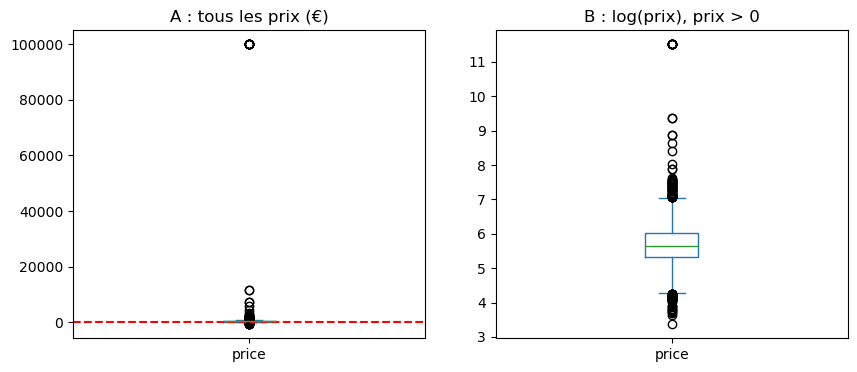

,price
count,6039.000000
mean,521.937981
std,4263.538353
min,-788.000000
25%,200.000000
50%,284.750000
75%,405.585000
max,99999.000000


Conclusion :
Le graphique A montre que la colonne price contient des valeurs impossibles :
- 32 prix négatifs et 21 prix nuls (53 prix ≤ 0) : un logement ne peut pas être loué gratuitement ou à perte ;
- 11 prix à 99 999 € : valeur-code (« placeholder »), pas un vrai prix ;
- quelques prix très élevés (5 000 à 12 000 €) : possibles mais suspects.

Le graphique B (échelle logarithmique) montre que la grande majorité des prix est cohérente :
la médiane est de 285 € par nuit, ce qui est plausible pour Amsterdam, car ~70 % des annonces
sont des logements entiers.

Décisions :
- prix négatifs → corriger (on retire le signe moins) : la valeur absolue est cohérente
  avec revenu ÷ nuits estimées pour 28 annonces sur 32 ;
- prix nuls et 99 999 → neutraliser (NaN) : la bonne valeur ne peut pas être retrouvée de façon fiable ;
- prix extrêmes (> 5 000 €) → vérifiés au cas par cas avec room_type et accommodates.


In [23]:
"""Valeurs impossibles : cherchez systématiquement les valeurs qui ne peuvent pas exister
(un prix, une capacité ou une durée qui n’ont pas de sens, une note hors de son échelle,
des dates incohérentes entre elles ou postérieures à la collecte, des coordonnées hors de la
ville, un avis rattaché à une annonce qui n’existe pas…). Pour chacune, décidez : corriger
(si la bonne valeur peut être retrouvée de façon fiable), neutraliser (valeur manquante)
ou écarter la ligne.
"""

import matplotlib.pyplot as plt
import numpy as np

prix = nouvelle_table_propre['price']
masque = prix > 0

print("Prix négatifs :", (prix < 0).sum())
print("Prix nuls     :", (prix == 0).sum())
print("Prix = 99 999 :", (prix == 99999).sum())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
prix.plot(kind='box', ax=axes[0], title='A : tous les prix (€)')
axes[0].axhline(0, color='red', linestyle='--')
np.log(prix[masque]).plot(kind='box', ax=axes[1], title='B : log(prix), prix > 0')
plt.show()

display(prix.describe().to_frame())

print("""Conclusion :
Le graphique A montre que la colonne price contient des valeurs impossibles :
- 32 prix négatifs et 21 prix nuls (53 prix ≤ 0) : un logement ne peut pas être loué gratuitement ou à perte ;
- 11 prix à 99 999 € : valeur-code (« placeholder »), pas un vrai prix ;
- quelques prix très élevés (5 000 à 12 000 €) : possibles mais suspects.

Le graphique B (échelle logarithmique) montre que la grande majorité des prix est cohérente :
la médiane est de 285 € par nuit, ce qui est plausible pour Amsterdam, car ~70 % des annonces
sont des logements entiers.

Décisions :
- prix négatifs → corriger (on retire le signe moins) : la valeur absolue est cohérente
  avec revenu ÷ nuits estimées pour 28 annonces sur 32 ;
- prix nuls et 99 999 → neutraliser (NaN) : la bonne valeur ne peut pas être retrouvée de façon fiable ;
- prix extrêmes (> 5 000 €) → vérifiés au cas par cas avec room_type et accommodates.""")





In [24]:
# prix négatifs → corriger (on retire le signe moins) 
nouvelle_table_propre['price'] = nouvelle_table_propre['price'].abs()

# prix nuls et 99 999 → neutraliser (NaN) : la bonne valeur ne peut pas être retrouvée de façon fiable
masque_code = (nouvelle_table_propre['price'] == 0) | (nouvelle_table_propre['price'] == 99999)
nouvelle_table_propre.loc[masque_code, 'price'] = np.nan

# prix extrêmes (> 5 000 €) : annonces quasi inactives (0 nuit réservée sur l'année, sauf une).
#    3 annonces pour 2–4 personnes ont un prix incohérent (> 2 800 €/pers.) → neutralisées (NaN),
#    ainsi que le revenu de l'une d'elles, calculé à partir de ce prix erroné.
#    Les 2 grands logements de groupe (16 pers., 450 €/pers.) sont conservés.
prix_par_pers = nouvelle_table_propre['price'] / nouvelle_table_propre['accommodates']
masque_extreme = (nouvelle_table_propre['price'] > 5000) & (prix_par_pers > 1000)

display(nouvelle_table_propre.loc[masque_extreme, ['price', 'room_type', 'accommodates',
                                                   'estimated_occupancy_l365d', 'estimated_revenue_l365d']])

masque_revenu = masque_extreme & (nouvelle_table_propre['estimated_occupancy_l365d'] > 0)
nouvelle_table_propre.loc[masque_revenu, 'estimated_revenue_l365d'] = np.nan
nouvelle_table_propre.loc[masque_extreme, 'price'] = np.nan

 

,price,room_type,accommodates,estimated_occupancy_l365d,estimated_revenue_l365d
2141,5706.0,entire home/apt,2,0,0.0
3699,11581.2,entire home/apt,2,0,0.0
9544,11681.0,entire home/apt,4,8,93448.0


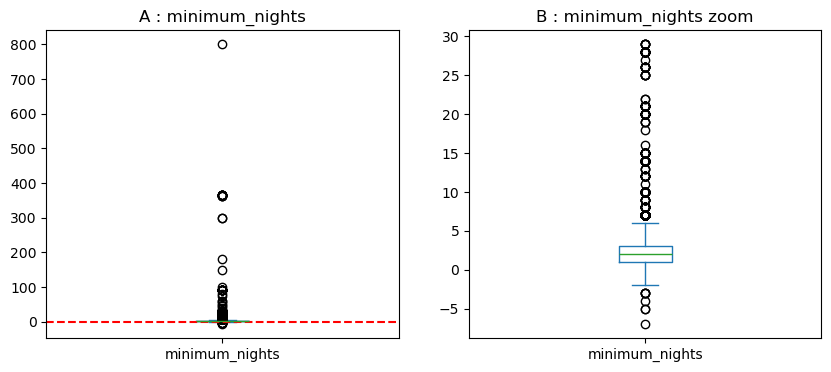

count    10612.000000
mean         3.713098
std         15.556216
min         -7.000000
25%          1.000000
50%          2.000000
75%          3.000000
max        800.000000
Name: minimum_nights, dtype: float64
Conclusion minimum_nights :
- la majorité des annonces exige 1 à 3 nuits minimum (médiane : 2) ;
- valeurs impossibles : 21 durées ≤ 0  ;
- valeurs extrêmes : 82 annonces ≥ 30 nuits (location moyenne/longue durée, plausible),
  dont 4 ≥ 365 nuits et une à 800 nuits (plus de 2 ans : aberrant.)


In [25]:
"""Valeurs aberrantes: minimum_nights.
– Détection par quantiles et boxplot.
"""




describe=nouvelle_table_propre['minimum_nights'].describe()

nights=nouvelle_table_propre['minimum_nights']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
nights.plot(kind='box', ax=axes[0], title='A : minimum_nights')
axes[0].axhline(0, color='red', linestyle='--')
nights[nights < 30].plot(kind='box', ax=axes[1], title='B : minimum_nights zoom')

plt.show()
print(describe)

print("""Conclusion minimum_nights :
- la majorité des annonces exige 1 à 3 nuits minimum (médiane : 2) ;
- valeurs impossibles : 21 durées ≤ 0  ;
- valeurs extrêmes : 82 annonces ≥ 30 nuits (location moyenne/longue durée, plausible),
  dont 4 ≥ 365 nuits et une à 800 nuits (plus de 2 ans : aberrant.)""")

In [26]:
"""– Règle de traitement justifiée.
• Lignes écartées conservées dans un DataFrame de rejet, avec le motif."""


# durées impossibles (≤ 0) et aberrantes (> 365 nuits) → neutraliser (NaN)


masque_nuits = (nouvelle_table_propre['minimum_nights'] <= 0) | (nouvelle_table_propre['minimum_nights'] > 365)
# Durées à neutralisées : masque_nuits.sum()-> 22

nouvelle_table_propre.loc[masque_nuits, 'minimum_nights'] = np.nan


# valeurs non entières → arrondies à l'entier
nouvelle_table_propre['minimum_nights'] = nouvelle_table_propre['minimum_nights'].round()

# contrôle final
nights = nouvelle_table_propre['minimum_nights']
print("Durées ≤ 0 restantes   :", (nights <= 0).sum())        
print("Durées > 365 restantes :", (nights > 365).sum())       
print("Durées non entières    :", ((nights % 1 != 0) & nights.notna()).sum())    


rejets = pd.concat([rejet_dup, rejet_id])

print("Lignes écartées au total :", len(rejets))              



Durées ≤ 0 restantes   : 0
Durées > 365 restantes : 0
Durées non entières    : 0
Lignes écartées au total : 138


In [27]:
"""Incohérences : neighbourhood_cleansed
83 écritures différentes pour 22 quartiers officiels (majuscules, espaces,
tiret remplacé par un espace…) → corriger d'après neighbourhoods.csv"""

quartiers = pd.read_csv('neighbourhoods.csv')

def cle(serie):                       # 'CENTRUM-WEST', ' Centrum West ' → 'centrumwest'
    return serie.str.lower().str.replace(r'[^a-z]', '', regex=True)

reference = dict(zip(cle(quartiers['neighbourhood']), quartiers['neighbourhood']))

nb_variantes_avant = nouvelle_table_propre['neighbourhood_cleansed'].nunique()
nouvelle_table_propre['neighbourhood_cleansed'] = cle(nouvelle_table_propre['neighbourhood_cleansed']).map(reference)

print("Écritures différentes avant :", nb_variantes_avant)                                         # 83
print("Quartiers après             :", nouvelle_table_propre['neighbourhood_cleansed'].nunique())   # 22
print("Non reconnus (NaN)          :", nouvelle_table_propre['neighbourhood_cleansed'].isna().sum())  # 0


Écritures différentes avant : 83
Quartiers après             : 22
Non reconnus (NaN)          : 0


In [28]:
"""Valeurs impossibles : accommodates et dates d'avis"""

# accommodates = 0 : un logement pour 0 personne est impossible → neutraliser
masque_acc = nouvelle_table_propre['accommodates'] == 0
nouvelle_table_propre.loc[masque_acc, 'accommodates'] = np.nan

# last_review postérieur à la collecte (avis « du futur », ex. 2028) → neutraliser
masque_futur = nouvelle_table_propre['last_review'] > nouvelle_table_propre['last_scraped']
nouvelle_table_propre.loc[masque_futur, 'last_review'] = pd.NaT

# first_review postérieur à last_review : on ne sait pas laquelle est fausse → neutraliser les deux
masque_ordre = nouvelle_table_propre['first_review'] > nouvelle_table_propre['last_review']
nouvelle_table_propre.loc[masque_ordre, ['first_review', 'last_review']] = pd.NaT

print("accommodates = 0 sont neutralisés           :", masque_acc.sum())     # 18
print("last_review dans le futur neutralisés  :", masque_futur.sum())   # 21
print("first_review > last_review neutralisés :", masque_ordre.sum())   # 53

accommodates = 0 sont neutralisés           : 18
last_review dans le futur neutralisés  : 21
first_review > last_review neutralisés : 53


In [29]:
"""A5 — Doublons et valeurs impossibles dans reviews"""

reviews_propre = reviews.drop(columns='reviewer_name').copy()     # données personnelles : on ne les garde pas
n_depart = len(reviews_propre)

# 1. doublons exacts → écarter
masque = reviews_propre.duplicated()
rejet_rev_dup = reviews_propre[masque].copy()
rejet_rev_dup['motif'] = 'reviews : doublon exact'
reviews_propre = reviews_propre[~masque]

# 2. même avis (id) rattaché à plusieurs annonces du même hôte → garder une seule copie
masque = reviews_propre.duplicated(subset='id')
rejet_rev_id = reviews_propre[masque].copy()
rejet_rev_id['motif'] = "reviews : même avis copié sur plusieurs annonces de l'hôte"
reviews_propre = reviews_propre[~masque]

# 3. dates : deux formats (ISO et jj/mm/aaaa) → corriger
iso = pd.to_datetime(reviews_propre['date'], format='%Y-%m-%d', errors='coerce')
fr  = pd.to_datetime(reviews_propre['date'], format='%d/%m/%Y', errors='coerce')
reviews_propre['date'] = iso.fillna(fr)
print("Dates illisibles :", reviews_propre['date'].isna().sum())        
# 4. avis postérieurs à la collecte (2027) → écarter
date_collecte = nouvelle_table_propre['last_scraped'].max()
masque = reviews_propre['date'] > date_collecte
rejet_rev_futur = reviews_propre[masque].copy()
rejet_rev_futur['motif'] = 'reviews : date postérieure à la collecte'
reviews_propre = reviews_propre[~masque]

# 5. avis rattachés à une annonce absente de listings → écarter
masque = ~reviews_propre['listing_id'].isin(nouvelle_table_propre['id'])
rejet_rev_orphelin = reviews_propre[masque].copy()
rejet_rev_orphelin['motif'] = "reviews : annonce inexistante dans listings"
reviews_propre = reviews_propre[~masque]

print("Avis au départ  :", n_depart)
print("Avis conservés  :", len(reviews_propre))
print("Avis écartés    :", n_depart - len(reviews_propre))

Dates illisibles : 0
Avis au départ  : 577646
Avis conservés  : 552748
Avis écartés    : 24898


In [30]:
"""Tableau des anomalies détectées : fichier, type d'anomalie, colonnes,
nombre de lignes, traitement appliqué."""

anomalies = pd.DataFrame([
    {'fichier': 'listings', "type d'anomalie": 'doublons exacts',
     'colonnes': 'toutes', 'nombre de lignes': len(rejet_dup),
     'traitement appliqué': 'écarter (DataFrame de rejet)'},
    {'fichier': 'listings', "type d'anomalie": 'doublons partiels (même id, prix +10 %)',
     'colonnes': 'id, price', 'nombre de lignes': len(rejet_id),
     'traitement appliqué': 'écarter : prix cohérent avec revenu ÷ nuits conservé'},
    {'fichier': 'listings', "type d'anomalie": 'prix négatifs',
     'colonnes': 'price', 'nombre de lignes': 32,
     'traitement appliqué': 'corriger : valeur absolue'},
    {'fichier': 'listings', "type d'anomalie": 'prix nuls',
     'colonnes': 'price', 'nombre de lignes': 21,
     'traitement appliqué': 'neutraliser (NaN)'},
    {'fichier': 'listings', "type d'anomalie": 'valeur sentinelle 99 999 €',
     'colonnes': 'price', 'nombre de lignes': 11,
     'traitement appliqué': 'neutraliser (NaN)'},
    {'fichier': 'listings', "type d'anomalie": 'prix extrêmes incohérents (> 2 800 €/pers.)',
     'colonnes': 'price, estimated_revenue_l365d', 'nombre de lignes': masque_extreme.sum(),
     'traitement appliqué': 'neutraliser (NaN) prix + revenu calculé dessus'},
    {'fichier': 'listings', "type d'anomalie": 'durée minimale ≤ 0 ou > 365 nuits',
     'colonnes': 'minimum_nights', 'nombre de lignes': masque_nuits.sum(),
     'traitement appliqué': 'neutraliser (NaN)'},
    {'fichier': 'listings', "type d'anomalie": 'capacité nulle (0 personne)',
     'colonnes': 'accommodates', 'nombre de lignes': masque_acc.sum(),
     'traitement appliqué': 'neutraliser (NaN)'},
    {'fichier': 'listings', "type d'anomalie": 'dernier avis postérieur à la collecte',
     'colonnes': 'last_review', 'nombre de lignes': masque_futur.sum(),
     'traitement appliqué': 'neutraliser (NaT)'},
    {'fichier': 'listings', "type d'anomalie": 'premier avis postérieur au dernier',
     'colonnes': 'first_review, last_review', 'nombre de lignes': masque_ordre.sum(),
     'traitement appliqué': 'neutraliser (NaT) les deux dates'},
    {'fichier': 'listings', "type d'anomalie": f'quartiers écrits de plusieurs façons ({nb_variantes_avant} écritures → 22)',
     'colonnes': 'neighbourhood_cleansed', 'nombre de lignes': '—',
     'traitement appliqué': 'corriger : alignement sur neighbourhoods.csv'},
 {'fichier': 'reviews', "type d'anomalie": 'doublons exacts',
     'colonnes': 'toutes', 'nombre de lignes': len(rejet_rev_dup),
     'traitement appliqué': 'écarter (DataFrame de rejet)'},
    {'fichier': 'reviews', "type d'anomalie": "même avis (id) copié sur plusieurs annonces du même hôte",
     'colonnes': 'id, listing_id', 'nombre de lignes': len(rejet_rev_id),
     'traitement appliqué': 'écarter les copies : un avis compté une seule fois'},
    {'fichier': 'reviews', "type d'anomalie": 'dates au format jj/mm/aaaa',
     'colonnes': 'date', 'nombre de lignes': (iso.isna() & fr.notna()).sum(),
     'traitement appliqué': 'corriger : lecture des deux formats'},
    {'fichier': 'reviews', "type d'anomalie": 'date postérieure à la collecte (2027)',
     'colonnes': 'date', 'nombre de lignes': len(rejet_rev_futur),
     'traitement appliqué': 'écarter (DataFrame de rejet)'},
    {'fichier': 'reviews', "type d'anomalie": 'avis rattaché à une annonce inexistante',
     'colonnes': 'listing_id', 'nombre de lignes': len(rejet_rev_orphelin),
     'traitement appliqué': 'écarter (DataFrame de rejet)'},
    {'fichier': 'reviews', "type d'anomalie": 'données personnelles (nom du voyageur)',
     'colonnes': 'reviewer_name', 'nombre de lignes': len(reviews),
     'traitement appliqué': 'colonne supprimée (protection des données)'},
])

with pd.option_context('display.max_colwidth', None):
    display(anomalies)
    

,fichier,type d'anomalie,colonnes,nombre de lignes,traitement appliqué
0,listings,doublons exacts,toutes,106,écarter (DataFrame de rejet)
1,listings,"doublons partiels (même id, prix +10 %)","id, price",32,écarter : prix cohérent avec revenu ÷ nuits conservé
2,listings,prix négatifs,price,32,corriger : valeur absolue
3,listings,prix nuls,price,21,neutraliser (NaN)
4,listings,valeur sentinelle 99 999 €,price,11,neutraliser (NaN)
5,listings,prix extrêmes incohérents (> 2 800 €/pers.),"price, estimated_revenue_l365d",3,neutraliser (NaN) prix + revenu calculé dessus
6,listings,durée minimale ≤ 0 ou > 365 nuits,minimum_nights,22,neutraliser (NaN)
7,listings,capacité nulle (0 personne),accommodates,18,neutraliser (NaN)
8,listings,dernier avis postérieur à la collecte,last_review,21,neutraliser (NaT)
9,listings,premier avis postérieur au dernier,"first_review, last_review",53,neutraliser (NaT) les deux dates


In [31]:
"""A6 Contrôles, bilan et signature
• Écrivez au moins 10 contrôles de cohérence en Pandas. Chacun aﬀiche le nombre de
lignes en défaut.""" 


L = nouvelle_table_propre          # listings nettoyé
R = reviews_propre                 # reviews nettoyé
date_collecte = L['last_scraped'].max()
quartiers_officiels = pd.read_csv('neighbourhoods.csv')['neighbourhood']

controles = {
    'listings : id unique':                          L['id'].duplicated().sum(),
    'listings : price > 0':                          (L['price'] <= 0).sum(),
    'listings : minimum_nights entre 1 et 365':      (L['minimum_nights'].notna() & ~L['minimum_nights'].between(1, 365)).sum(),
    'listings : accommodates ≥ 1':                   (L['accommodates'] < 1).sum(),
    'listings : availability_365 entre 0 et 365':    (~L['availability_365'].between(0, 365)).sum(),
    'listings : bedrooms ≥ 0':                       (L['bedrooms'] < 0).sum(),
    'listings : last_review ≥ first_review':         (L['last_review'] < L['first_review']).sum(),
    'listings : last_review ≤ date de collecte':     (L['last_review'] > date_collecte).sum(),
    'listings : quartier dans neighbourhoods.csv':   (~L['neighbourhood_cleansed'].isin(quartiers_officiels)).sum(),
    'listings : room_type parmi 4 modalités':        (~L['room_type'].isin(['entire home/apt', 'private room', 'hotel room', 'shared room'])).sum(),
    'listings : statut_licence parmi 3 modalités':   (~L['statut_licence'].isin(['renseigné', 'exempté', 'non renseigné'])).sum(),
    'reviews : id unique':                           R['id'].duplicated().sum(),
    'reviews : listing_id présent dans listings':    (~R['listing_id'].isin(L['id'])).sum(),
    'reviews : date ≤ date de collecte':             (R['date'] > date_collecte).sum(),
}

tableau_controles = pd.DataFrame.from_dict(controles, orient='index', columns=['lignes en défaut'])
display(tableau_controles)
print("Contrôles en défaut :", (tableau_controles['lignes en défaut'] > 0).sum())  

,lignes en défaut
listings : id unique,0
listings : price > 0,0
listings : minimum_nights entre 1 et 365,0
listings : accommodates ≥ 1,0
listings : availability_365 entre 0 et 365,0
listings : bedrooms ≥ 0,0
listings : last_review ≥ first_review,0
listings : last_review ≤ date de collecte,0
listings : quartier dans neighbourhoods.csv,0
listings : room_type parmi 4 modalités,0


Contrôles en défaut : 0


In [32]:
"""A6 | Bilan avant / après : lignes, colonnes, % global de manquants, lignes rejetées par motif"""

def bilan(df):
    return {'lignes': df.shape[0], 'colonnes': df.shape[1],
            '% manquants (global)': round(df.isna().mean().mean() * 100, 2)}

bilan_tables = pd.DataFrame({
    'listings avant':  bilan(listings),
    'listings après':  bilan(nouvelle_table_propre),
    'reviews avant':   bilan(reviews),
    'reviews après':   bilan(reviews_propre),
}).T
display(bilan_tables)

rejets = pd.concat([rejet_dup, rejet_id,
                    rejet_rev_dup, rejet_rev_id, rejet_rev_futur, rejet_rev_orphelin])
print("Lignes rejetées par motif :")
display(rejets['motif'].value_counts().to_frame('lignes rejetées'))




,lignes,colonnes,% manquants (global)
listings avant,10750.0,90.0,21.45
listings après,10612.0,29.0,3.85
reviews avant,577646.0,6.0,0.03
reviews après,552748.0,5.0,0.03


Lignes rejetées par motif :


,lignes rejetées
motif,
reviews : même avis copié sur plusieurs annonces de l'hôte,16954
reviews : doublon exact,5719
reviews : annonce inexistante dans listings,1667
reviews : date postérieure à la collecte,558
doublon exact (ligne identique),106
doublon partiel sur id : prix incohérent avec revenu ÷ nuits (+10 %),32


In [33]:
import hashlib
import pandas as pd


def signature(df, nom):
    """Résumé détaillé et empreinte d'une table nettoyée."""
    copie = df.copy()
    for col in copie.columns:
        # les listes (ex. amenities) sont converties en texte pour pouvoir être résumées
        if copie[col].map(lambda v: isinstance(v, (list, dict, set, tuple))).any():
            copie[col] = copie[col].map(str)
    empreinte = hashlib.md5(
        pd.util.hash_pandas_object(copie.astype(str), index=False).values.tobytes()
    ).hexdigest()

    print(f"=== Signature : {nom} ===")
    print(f"Lignes : {copie.shape[0]}          Colonnes : {copie.shape[1]}")
    print(f"Empreinte MD5 : {empreinte}")
    resume = pd.DataFrame({
        "type": copie.dtypes.astype(str),
        "manquants": copie.isna().sum(),
        "pct_manquants": (copie.isna().mean() * 100).round(2),
        "valeurs_distinctes": copie.nunique(),
    })
    display(resume)
    numeriques = copie.select_dtypes("number")
    if not numeriques.empty:
        display(numeriques.describe().T.round(2))
    return empreinte


signature(nouvelle_table_propre, "listings nettoyé")
signature(reviews_propre, "reviews nettoyé")



=== Signature : listings nettoyé ===
Lignes : 10612          Colonnes : 29
Empreinte MD5 : 586a1a7127e4a2964517caab08a3243a


,type,manquants,pct_manquants,valeurs_distinctes
number_of_reviews_ltm,int64,0,0.00,167
last_review,datetime64[ns],1076,10.14,1530
availability_365,int64,0,0.00,366
calculated_host_listings_count,int64,0,0.00,20
room_type,object,0,0.00,4
price,float64,4608,43.42,3069
accommodates,float64,18,0.17,15
hosts_time_as_host_months,int64,0,0.00,12
hosts_time_as_host_years,int64,0,0.00,16
amenities,object,0,0.00,10048


,count,mean,std,min,25%,50%,75%,max
number_of_reviews_ltm,10612.0,9.670000e+00,2.805000e+01,0.0,0.00,2.000000e+00,6.000000e+00,8.780000e+02
availability_365,10612.0,9.362000e+01,1.236200e+02,0.0,0.00,1.400000e+01,1.782500e+02,3.650000e+02
calculated_host_listings_count,10612.0,1.830000e+00,2.690000e+00,1.0,1.00,1.000000e+00,1.000000e+00,2.400000e+01
price,6004.0,3.405500e+02,2.598100e+02,29.0,202.00,2.852400e+02,4.070000e+02,7.200000e+03
accommodates,10594.0,3.060000e+00,3.710000e+00,1.0,2.00,2.000000e+00,4.000000e+00,9.900000e+01
hosts_time_as_host_months,10612.0,5.090000e+00,3.520000e+00,0.0,2.00,5.000000e+00,8.000000e+00,1.100000e+01
hosts_time_as_host_years,10612.0,5.830000e+00,4.290000e+00,0.0,2.00,6.000000e+00,1.000000e+01,1.500000e+01
minimum_nights,10590.0,3.650000e+00,1.351000e+01,1.0,1.00,2.000000e+00,3.000000e+00,3.650000e+02
host_id,10612.0,1.175083e+16,1.412198e+17,3592.0,13764503.00,5.042165e+07,2.162271e+08,1.768224e+18
id,10612.0,7.314719e+17,6.409643e+17,28871.0,30500029.00,8.339275e+17,1.303882e+18,1.774618e+18


=== Signature : reviews nettoyé ===
Lignes : 552748          Colonnes : 5
Empreinte MD5 : 26b4090f9d6521287afcdd7ad4925871


,type,manquants,pct_manquants,valeurs_distinctes
listing_id,int64,0,0.00,9608
id,int64,0,0.00,552748
date,datetime64[ns],0,0.00,5366
reviewer_id,int64,0,0.00,531175
comments,object,959,0.17,534619


,count,mean,std,min,25%,50%,75%,max
listing_id,552748.0,2.110252e+17,4.368565e+17,28871.0,7.190115e+06,2.230520e+07,4.947331e+07,1.765473e+18
id,552748.0,8.061556e+17,6.282130e+17,82539.0,5.237997e+08,8.969836e+17,1.382564e+18,1.776640e+18
reviewer_id,552748.0,4.368977e+15,8.628185e+16,1.0,3.998140e+07,1.276912e+08,3.233623e+08,1.771895e+18


'26b4090f9d6521287afcdd7ad4925871'

In [34]:
"""A6 | Export des tables nettoyées"""

nouvelle_table_propre.to_csv('listings_propre.csv', index=False)
reviews_propre.to_csv('reviews_propre.csv', index=False)
print("Tables exportées : listings_propre.csv, reviews_propre.csv")



Tables exportées : listings_propre.csv, reviews_propre.csv
